# 01. Mengenal Lite tracker

Notebook ini tidak butuh video, detektor, atau data apa pun. Semua jalan dalam beberapa detik.

**Isinya:**
1. Adegan CCTV sintetis: 5 orang dengan kasus yang biasa menyulitkan tracker (tertutup forklift, berpapasan, deteksi ragu-ragu, box dobel, deteksi palsu). Label ID yang benar ikut dibuat.
2. Menjalankan Lite tracker di 4 FPS dan melihat ID tiap orang sepanjang waktu.
3. Mengubah satu hal (FPS, waktu ingat, deteksi ragu) dan melihat akibatnya.
4. Cara memasang Lite ke pipeline: `PersonTracker` (umum) dan `LiteForComplianceTracker` (pengganti langsung di pipeline utama).

Penjelasan langkah demi langkah ada di `docs/LITE_TRACKER.md` dan gambar di `docs/ilustrasi/`.

**Catatan.** Adegan sintetis ini untuk memahami cara kerja, bukan untuk menilai tracker mana yang terbaik. Penilaian yang sebenarnya ada di notebook 02 (CCTV PT SRP), notebook 03 (MOT17, label manusia), dan nanti evaluasi dengan video ground truth.

In [1]:
# Cek Python yang dipakai notebook. Harus .venv milik repo ini.
import sys, importlib.util
print("Python:", sys.executable)
missing = [m for m in ('numpy', 'scipy', 'pandas', 'matplotlib') if importlib.util.find_spec(m) is None]
if ".venv" not in sys.executable or missing:
    raise RuntimeError(
        "Notebook belum memakai .venv proyek" + (f" (paket tidak ada: {', '.join(missing)})" if missing else "") + ".\n"
        "Jalankan `uv sync` di folder repo, lalu di VS Code: klik nama kernel di kanan atas > Select Another Kernel > "
        "Python Environments > .venv (object-tracking), atau Enter interpreter path: "
        "~/Documents/GitHub/object-tracking/.venv/bin/python"
    )
print("ok, semua paket ada")

Python: /Users/rdrusdiati/Documents/GitHub/object-tracking/.venv/bin/python
ok, semua paket ada


## 0. Pengaturan

In [2]:
import sys, warnings
from pathlib import Path
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

from object_tracking import PersonTracker, load_lite_config, LITE_TUNED_PARAMS
from object_tracking import synthetic as syn

cfg, inp = load_lite_config()           # parameter "Lite tuned"
print("Parameter Lite tuned:")
display(pd.Series({**LITE_TUNED_PARAMS, **inp}, name="nilai").to_frame())

Parameter Lite tuned:


,nilai
high_thresh,0.517
low_thresh,0.1
new_thresh,0.535
min_iou,0.365
min_iou_low,0.386
buffers,"(0.1,)"
max_lost_sec,4.159
lost_velocity_decay_sec,1.455
confirm_hits,2
std_vel,0.886


## 1. Adegan sintetis

Kamera 1280x720, 20 detik. Garis = jalur kaki tiap orang, bagian putus-putus = orang tertutup penuh (tidak ada deteksi sama sekali).

| Orang | Kasus |
|---|---|
| 1 | Berjalan ke kanan, tertutup forklift 2,5 detik (detik 6 sampai 8,5) |
| 2 | Berjalan ke kiri, berpapasan dengan orang 1 |
| 3 | Jauh dari kamera (box kecil), gerak pelan |
| 4 | Baru masuk di detik 9, tertutup 1 detik |
| 5 | Berdiri diam di dekat rak |

Di sekitar saat tertutup, deteksinya ragu-ragu (skor 0,2 sampai 0,45). Ada juga box dobel berskor rendah dan deteksi palsu sesekali, seperti keluaran detektor sungguhan.

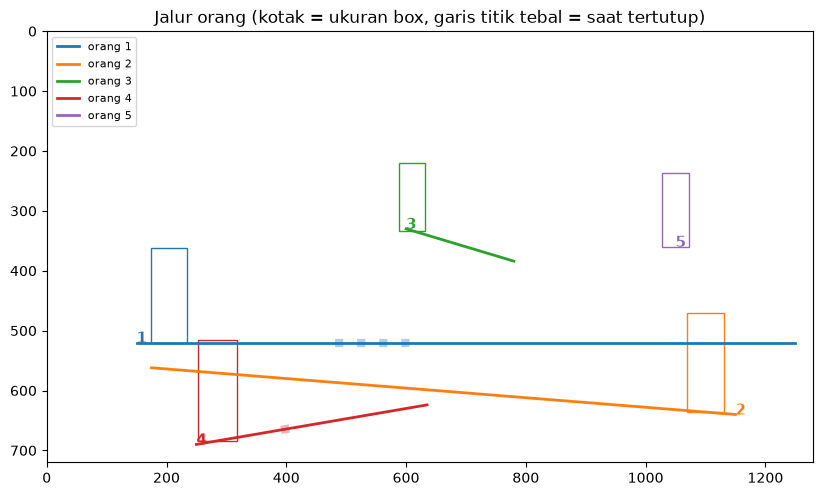

251 frame pada 12.5 FPS, 1110 deteksi, termasuk 123 deteksi skor < 0,5


In [3]:
scene = syn.make_scene(duration=20, fps=12.5, seed=0)
fig, ax = plt.subplots(figsize=(10, 5.6))
for p in scene["people"]:
    ts = np.linspace(p.t_in, p.t_out, 200)
    feet = np.array([[(p.box(t)[0] + p.box(t)[2]) / 2, p.box(t)[3]] for t in ts])
    hidden = np.array([p.state(t) == "hidden" for t in ts])
    line, = ax.plot(feet[:, 0], feet[:, 1], lw=2, label=f"orang {p.pid}")
    ax.plot(np.where(hidden, feet[:, 0], np.nan), np.where(hidden, feet[:, 1], np.nan), lw=6, alpha=0.35, color=line.get_color(), ls=":")
    ax.annotate(f"{p.pid}", feet[0], fontsize=11, weight="bold", color=line.get_color())
    b = p.box(p.t_in + 1.0)
    ax.add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, color=line.get_color(), lw=1))
ax.set_xlim(0, 1280); ax.set_ylim(720, 0); ax.set_aspect("equal")
ax.set_title("Jalur orang (kotak = ukuran box, garis titik tebal = saat tertutup)")
ax.legend(loc="upper left", fontsize=8)
plt.show()
n_det = sum(len(d) for d in scene["dets"])
print(f"{len(scene['t'])} frame pada {scene['fps']} FPS, {n_det} deteksi, termasuk {sum((d[:, 4] < 0.5).sum() for d in scene['dets'])} deteksi skor < 0,5")

## 2. Lite tracker di 4 FPS

Satu `PersonTracker` untuk satu kamera. Setiap frame yang diproses, berikan **semua** box orang beserta skornya dan waktunya dalam detik. Penyaringan skor, NMS box dobel, dan pembagian deteksi yakin vs ragu dilakukan di dalam tracker.

IDF1 0.879 | HOTA 0.749 | ID switch 1 | ID dibuat 6 (orang sebenarnya 5)


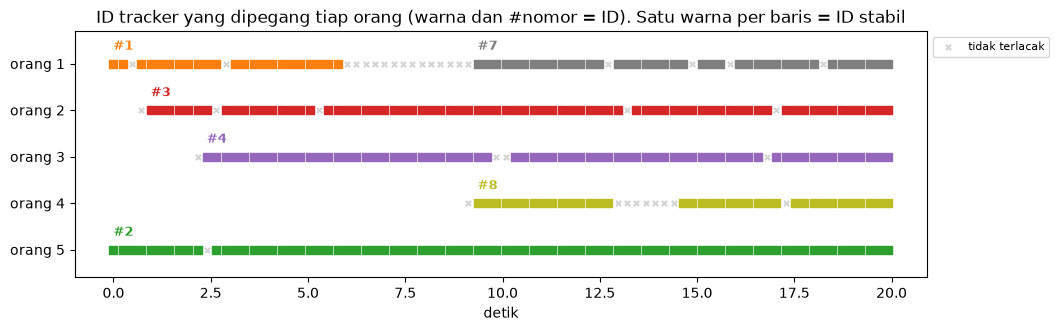

In [4]:
def run_lite(scene, fps=4.0, cfg_over=None, inp_over=None):
    c, i = load_lite_config()
    trk = PersonTracker(replace(c, **(cfg_over or {})), **{**i, **(inp_over or {})})
    step = max(1, int(round(scene["fps"] / fps)))
    hyp = []
    for k in range(0, len(scene["t"]), step):
        t, d = float(scene["t"][k]), scene["dets"][k]
        out = trk.update(d[:, :4], d[:, 4], t)                 # <- inti pemakaian tracker
        hyp.append((t, [(o.id, o.box) for o in out]))
    return hyp, trk

hyp, trk = run_lite(scene, fps=4)
m = syn.evaluate(scene, hyp)
print(f"IDF1 {m['IDF1']:.3f} | HOTA {m['HOTA']:.3f} | ID switch {m['IDSW']} | ID dibuat {m['IDs']} (orang sebenarnya {m['GT_IDs']})")

def plot_timeline(scene, hyp, title):
    tl = pd.DataFrame(syn.id_timeline(scene, hyp), columns=["t", "orang", "id"])
    fig, ax = plt.subplots(figsize=(11, 3.2))
    cmap = plt.get_cmap("tab10")
    for (orang, tid), g in tl[tl.id >= 0].groupby(["orang", "id"]):
        ax.scatter(g.t, [orang] * len(g), color=cmap(tid % 10), s=28, marker="s")
        ax.annotate(f"#{tid}", (g.t.iloc[0], orang - 0.3), fontsize=9, weight="bold", color=cmap(tid % 10))
    miss = tl[tl.id < 0]
    ax.scatter(miss.t, miss.orang, color="lightgray", s=14, marker="x", label="tidak terlacak")
    ax.set_yticks(sorted(tl.orang.unique()), [f"orang {o}" for o in sorted(tl.orang.unique())])
    ax.set_xlabel("detik"); ax.set_title(title); ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
    ax.set_ylim(max(tl.orang) + 0.6, min(tl.orang) - 0.7)
    plt.show()

plot_timeline(scene, hyp, "ID tracker yang dipegang tiap orang (warna dan #nomor = ID). Satu warna per baris = ID stabil")

**Cara membaca.** Setiap baris adalah satu orang sebenarnya. Kalau warnanya sama dari awal sampai akhir, ID-nya stabil. Kalau warnanya berganti di tengah, terjadi ID switch. Tanda x abu-abu berarti orang itu tidak terlacak di frame tersebut, misalnya saat tertutup penuh, atau baru muncul dan belum dikonfirmasi (ID baru tampil setelah terlihat 2 kali).

Perhatikan orang 1 setelah tertutup 2,5 detik. Selama tertutup, tracker menebak posisinya dari kecepatan terakhir, tapi setelah 1,5 detik tebakan dihentikan (dianggap diam) supaya box tidak "terbang". Kalau orangnya terus berjalan jauh selama tertutup, posisi muncul kembali bisa terlalu jauh dari tebakan, sehingga ID baru dibuat. Ini batas yang wajar untuk tracker tanpa Re-ID (tanpa mengenali penampilan).

## 3. Apa yang terjadi kalau...

Satu hal diubah, yang lain tetap seperti Lite tuned. Hasil di adegan kecil ini bisa berbeda untuk seed lain, jadi baca sebagai ilustrasi arah pengaruhnya.

In [5]:
variants = {
    "Lite tuned": ({}, {}),
    "ingat orang hilang 1 detik saja (bawaan 4,2)": ({"max_lost_sec": 1.0}, {}),
    "tanpa deteksi ragu (hanya skor >= 0,5)": ({}, {"person_min": 0.5}),
    "tanpa OCR dan ORU (dari OC-SORT)": ({"ocr": False, "oru": False}, {}),
    "tanpa box diperbesar (IoU biasa)": ({"buffers": (0.0,)}, {}),
    "langsung tampil (tanpa konfirmasi 2 kali)": ({"confirm_hits": 1}, {}),
}
rows = []
for seed in (0, 1, 2):
    sc = syn.make_scene(seed=seed)
    for fps in (2, 4, 6.25):
        for name, (co, io) in variants.items():
            h, _ = run_lite(sc, fps, co, io)
            r = syn.evaluate(sc, h)
            rows.append({"varian": name, "FPS": f"{fps:g} FPS", "seed": seed, "IDF1": r["IDF1"], "ID switch": r["IDSW"],
                         "ID dibuat": r["IDs"], "deteksi palsu ikut dilacak (FP)": r["FP"]})
df = pd.DataFrame(rows)
tab = df.groupby(["varian", "FPS"])[["IDF1", "ID switch", "ID dibuat", "deteksi palsu ikut dilacak (FP)"]].mean().unstack("FPS")
display(tab.loc[list(variants)].style.format("{:.2f}").background_gradient(cmap="Greens", subset=["IDF1"]))
print("rata-rata dari 3 seed adegan. Orang sebenarnya: 5")

rata-rata dari 3 seed adegan. Orang sebenarnya: 5


Yang biasanya terlihat:
- **FPS lebih rendah** membuat semua varian lebih sulit, karena jarak gerak antar frame makin jauh. Kalman berbasis detik di Lite membuat tebakan posisi tetap benar walau jarak antar frame berubah.
- **Ingat 1 detik saja** membuat orang yang tertutup lebih lama mendapat ID baru (ID dibuat naik).
- **Langsung tampil** membuat deteksi palsu sekilas ikut menjadi orang (FP naik). Konfirmasi 2 kali mencegahnya.

## 4. Cara memasang ke pipeline

### 4a. `PersonTracker`: untuk pipeline apa pun
Satu instance per kamera (atau pakai `CameraTrackers` yang membuatnya otomatis per kamera). Setiap orang yang keluar punya `det_idx`, yaitu indeks deteksi input yang cocok. Dengan indeks ini hasil asosiasi helm dan vest per deteksi bisa langsung disambungkan ke ID orang. `o.track.data` adalah dict bebas untuk menyimpan status per orang (misalnya status helm).

In [6]:
from object_tracking import CameraTrackers

cams = CameraTrackers()                                  # PersonTracker.tuned() per kamera
d = scene["dets"][0]
helm_per_deteksi = np.random.default_rng(0).random(len(d)) > 0.5   # contoh: hasil asosiasi helm per deteksi
for o in cams.update("kamera-01", d[:, :4], d[:, 4], timestamp_sec=0.0):
    pakai_helm = bool(helm_per_deteksi[o.det_idx])
    o.track.data.setdefault("helm", []).append(pakai_helm)
    print(f"ID {o.id}: box {np.round(o.box).astype(int).tolist()}, skor {o.score:.2f}, deteksi ke-{o.det_idx}, helm {pakai_helm}")

ID 1: box [123, 362, 178, 521], skor 0.69, deteksi ke-0, helm True
ID 2: box [1022, 235, 1073, 351], skor 0.79, deteksi ke-1, helm False


### 4b. `LiteForComplianceTracker`: pengganti langsung di pipeline utama
Pipeline utama (`hen-detect-ppe`) memakai `ComplianceTracker` yang di dalamnya memanggil tracker Ultralytics (`BYTETracker`). `LiteForComplianceTracker` punya input dan output yang sama (array N x 8: x1, y1, x2, y2, id, skor, kelas, indeks deteksi), jadi cukup ditambahkan sebagai pilihan `tracker_type="lite"`. Bedanya hanya satu: berikan juga `timestamp_sec`. Langkah lengkapnya ada di `docs/INTEGRASI.md`.

In [7]:
from object_tracking import LiteForComplianceTracker
from object_tracking.boxes import TrackerBoxes          # bentuk input yang sama dengan pipeline utama

eng = LiteForComplianceTracker(fps=4)
for k in range(0, 13, 3):                                # 4 FPS dari adegan 12,5 FPS
    t, d = float(scene["t"][k]), scene["dets"][k]
    xywh = np.stack([(d[:, 0] + d[:, 2]) / 2, (d[:, 1] + d[:, 3]) / 2, d[:, 2] - d[:, 0], d[:, 3] - d[:, 1]], 1)
    res = eng.update(TrackerBoxes(xywh, d[:, 4], np.zeros(len(d))), timestamp_sec=t)
print("kolom: x1, y1, x2, y2, track_id, skor, kelas, indeks deteksi")
with np.printoptions(suppress=True, precision=2):
    print(res)

kolom: x1, y1, x2, y2, track_id, skor, kelas, indeks deteksi
[[ 176.    359.92  233.46  515.03    1.      0.94    0.      0.  ]
 [1022.8   247.45 1073.29  352.93    2.      0.63    0.      2.  ]
 [1104.88  469.85 1160.75  637.39    3.      0.74    0.      1.  ]]


## Selanjutnya

| Notebook | Isi |
|---|---|
| `02_tuning_cctv.ipynb` | Tuning dan penilaian semua tracker di klip CCTV PT SRP (butuh detektor dan video) |
| `03_benchmark_mot17.ipynb` | Benchmark di MOT17 dengan label ID dari manusia |
| `04_bandingkan_tracker_video.ipynb` | Aplikasi Gradio: bandingkan tracker di video CCTV, live |